# Exercise 1.2: Territorial analysis I (3 points): Person A

Report chapter: `report/chapters/02_territorial_analysis_I.tex`

**Sub-questions**

1. Age distribution and average age (1 point)
2. Average age per municipality, youngest and oldest (1 point)
3. Socio-professional categories: study area and at least three municipalities (1 point)

**Two data sources** (see Ex. 1.1: only 17 of 528 municipalities are identifiable in the detailed census)

- **Detailed census** (`census_14.parquet` from Ex. 1.1; `age` = `AGEREV`, `age_aged` = `AGED`):
  single-year ages, department-level statistics, the 17 identifiable municipalities. Weighted by `weight` = `IPONDI`.
- **Aggregated census by IRIS, RP2019** "Population en 2019 – IRIS" (`base-ic-evol-struct-pop-2019.CSV`): all 528
  municipalities, age bands and population 15+ by SPC. Already weighted by INSEE (counts of persons).

**Reads**

- `data/processed/census_14.parquet`, `data/processed/municipalities.gpkg` (from Ex. 1.1)
- `data/raw/base-ic-evol-struct-pop-2019.CSV` (downloaded by the cell in "Data" if missing)

**Writes**

- `data/processed/population_14.parquet`: aggregated census per municipality (for Ex. 1.3 and 2.1)
- `data/processed/ex12_results.json`: all numbers reported in Section 1.2
- `report/figures/age_distribution.pdf`, `mean_age_map.pdf`, `spc_distribution.pdf` (+ `.png` previews)

## Setup and configuration

In [1]:
import json
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---- Study area ------------------------------------------------------------------------
DEPARTMENT = "14"            # INSEE code of Calvados (region Normandie)
DEPARTMENT_NAME = "Calvados"
CRS = "EPSG:2154"            # RGF93 / Lambert-93, metres; all geometries and distances

# ---- Paths -----------------------------------------------------------------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "report").is_dir())
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "report" / "figures"

CENSUS_PARQUET = DATA_PROCESSED / f"census_{DEPARTMENT}.parquet"   # from ex11: department, cantville, iris_id,
                                                                    # municipality_id, weight, age (= AGEREV),
                                                                    # age_aged (= AGED), csp
MUNICIPALITIES_GPKG = DATA_PROCESSED / "municipalities.gpkg"        # from ex11

# Aggregated census by IRIS, RP2019 "Population en 2019 - IRIS" (INSEE, https://www.insee.fr/fr/statistiques/6543200)
AGGREGATED_URL = "https://www.insee.fr/fr/statistiques/fichier/6543200/base-ic-evol-struct-pop-2019_csv.zip"
AGGREGATED_CSV = DATA_RAW / "base-ic-evol-struct-pop-2019.CSV"
AGGREGATED_META = DATA_RAW / "meta_base-ic-evol-struct-pop-2019.CSV"   # variable dictionary shipped in the zip

POPULATION_PARQUET = DATA_PROCESSED / f"population_{DEPARTMENT}.parquet"
RESULTS_JSON = DATA_PROCESSED / "ex12_results.json"

# ---- Socio-professional categories (CS1, PCS 2003 in 8 groups) ---------------------------
SPC_LABELS = {
    1: "Agriculteurs exploitants",
    2: "Artisans, commerçants et chefs d'entreprise",
    3: "Cadres et professions intellectuelles supérieures",
    4: "Professions intermédiaires",
    5: "Employés",
    6: "Ouvriers",
    7: "Retraités",
    8: "Autres personnes sans activité professionnelle",
}
SPC_COLUMNS = {k: f"C19_POP15P_CS{k}" for k in SPC_LABELS}          # aggregated census, population 15+

# ---- Age bands of the aggregated census (finest partition of P19_POP, completed years) -----
# (column, lower age, upper age); the open band 80+ gets the documented value AGE_OPEN_BAND below
AGE_BANDS = [
    ("P19_POP0002", 0, 2), ("P19_POP0305", 3, 5), ("P19_POP0610", 6, 10), ("P19_POP1117", 11, 17),
    ("P19_POP1824", 18, 24), ("P19_POP2539", 25, 39), ("P19_POP4054", 40, 54), ("P19_POP5564", 55, 64),
    ("P19_POP6579", 65, 79), ("P19_POP80P", 80, None),
]
AGE_OPEN_BAND = 85.0          # assumed mean age (completed years) of the band 80+; checked against the detailed census
MIN_POPULATION = 500          # threshold for the youngest / oldest municipality, variant (b)
RURAL_POPULATION = (500, 1500)  # population range for the rural example municipality in Section 3

# ---- Figures ---------------------------------------------------------------------------
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "legend.fontsize": 8, "pdf.fonttype": 42,
})
TEXT, TEXT_2, GRID = "#222222", "#666666", "#e6e6e6"
BLUE = "#257de0"                       # single series
REFERENCE = "#7a7a7a"                  # department (reference) in comparisons
AREA_COLORS = ["#257de0", "#f47230", "#00b894", "#6a4ce2"]   # categorical slots, fixed order
SEQUENTIAL = LinearSegmentedColormap.from_list(   # one hue, light -> dark
    "blues", ["#cce3fd", "#9dc8f7", "#6aabf1", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"])

TOWNS = {"14118": "Caen", "14047": "Bayeux", "14366": "Lisieux", "14762": "Vire Normandie"}  # as on the Ex. 1.1 map


def style_map_axes(ax):
    # Common map look: equal aspect, no axes frame or ticks
    ax.set_aspect("equal")
    ax.set_axis_off()
    return ax


def style_chart_axes(ax):
    # Recessive axes: no top/right spines, light grid behind the data
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(TEXT_2)
    ax.tick_params(colors=TEXT_2)
    ax.set_axisbelow(True)
    return ax


def scale_bar(ax, length_m, label, x_frac=0.06, y_frac=0.05):
    # Simple scale bar in map units (metres, Lambert-93)
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    ax.plot([x, x + length_m], [y, y], color=TEXT, lw=1.5, solid_capstyle="butt")
    ax.text(x + length_m / 2, y + 0.015 * (y1 - y0), label, ha="center", va="bottom", fontsize=7, color=TEXT)


def save_figure(fig, name, preview_png=False):
    # Vector PDF for the report (report/figures/<name>.pdf, \includegraphics{<name>}), optional PNG preview
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"{name}.pdf"
    fig.savefig(path, format="pdf", bbox_inches="tight")
    if preview_png:
        fig.savefig(path.with_suffix(".png"), format="png", dpi=150, bbox_inches="tight")
    return path


def weighted_median(values, weights):
    # Smallest value at which the cumulative weight reaches half of the total weight
    order = np.argsort(values, kind="stable")
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    return v[np.searchsorted(np.cumsum(w), 0.5 * w.sum())]


print("Study area:", DEPARTMENT, DEPARTMENT_NAME)

Study area: 14 Calvados


## Data

### Detailed census and the age variable

The detailed census has two single-year age variables (dictionary `Varmod_INDCVI_2019.csv`):

- `AGED`: "Âge détaillé (en différence de millésimes)", i.e. census year minus year of birth: the age the person
  reaches **during** the collection year. Stored as `age_aged` in `census_14.parquet`, only for this comparison.
- `AGEREV`: "Âge en années révolues détaillé", the age in **completed years** at the collection date. Stored as
  `age` in `census_14.parquet`: the age used everywhere in the project.

`AGEREV` is the usual meaning of "age", and it is the variable behind the age bands of the aggregated census
(checked below: the weighted band totals of the detailed file match the aggregated file with `AGEREV`, not with
`AGED`). We therefore use **`AGEREV`** (column `age`) for every age statistic.

In [2]:
df_census = pd.read_parquet(CENSUS_PARQUET)
assert {"age", "age_aged", "csp", "weight", "municipality_id"} <= set(df_census.columns)

print("observations:", len(df_census), "| persons:", df_census["weight"].sum())
print("AGED - AGEREV (observations):", (df_census["age_aged"] - df_census["age"]).value_counts().to_dict())
df_census.head()

observations: 171834 | persons: 695131.5553559497
AGED - AGEREV (observations): {1: 163229, 0: 8605}


,cantville,age_aged,age,csp,department,weight,iris_id,municipality_id
0,1401,92,91,7,14,5.000000,ZZZZZZZZZ,NaN
1,1401,72,71,7,14,5.120056,ZZZZZZZZZ,NaN
2,1401,70,69,7,14,5.120056,ZZZZZZZZZ,NaN
3,1401,32,31,5,14,5.161397,ZZZZZZZZZ,NaN
4,1401,27,26,6,14,5.161397,ZZZZZZZZZ,NaN


### Aggregated census by IRIS (RP2019)

"Population en 2019 – IRIS – France hors Mayotte" (INSEE). Downloaded once if it is not in `data/raw/` yet. Codes are
read as strings. Variable names were checked in the dictionary that comes with the file
(`meta_base-ic-evol-struct-pop-2019.CSV`, printed below): `P19_*` variables come from the *exploitation principale*
(all census answers), `C19_*` variables (SPC) from the *exploitation complémentaire* (a sample of the answers, the same
exploitation as the detailed file).

In [3]:
if not AGGREGATED_CSV.exists():
    zip_path = DATA_RAW / "base-ic-evol-struct-pop-2019_csv.zip"
    urllib.request.urlretrieve(AGGREGATED_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_RAW)
    zip_path.unlink()
    print("downloaded", AGGREGATED_CSV.relative_to(ROOT))
else:
    print("found", AGGREGATED_CSV.relative_to(ROOT))

used = ["IRIS", "COM", "P19_POP", "C19_POP15P", *[c for c, _, _ in AGE_BANDS], *SPC_COLUMNS.values()]
meta = pd.read_csv(AGGREGATED_META, sep=";", dtype=str).drop_duplicates("COD_VAR").set_index("COD_VAR")
with pd.option_context("display.max_colwidth", 90):
    display(meta.loc[used, ["LIB_VAR"]])

found data\raw\base-ic-evol-struct-pop-2019.CSV


,LIB_VAR
COD_VAR,
IRIS,IRIS
COM,Commune ou ARM
P19_POP,Population en 2019 (princ)
C19_POP15P,Pop 15 ans ou plus en 2019 (compl)
P19_POP0002,Pop 0-2 ans en 2019 (princ)
P19_POP0305,Pop 3-5 ans en 2019 (princ)
P19_POP0610,Pop 6-10 ans en 2019 (princ)
P19_POP1117,Pop 11-17 ans en 2019 (princ)
P19_POP1824,Pop 18-24 ans en 2019 (princ)


In [4]:
df_agg_iris = pd.read_csv(AGGREGATED_CSV, sep=";", dtype={"IRIS": str, "COM": str, "TYP_IRIS": str,
                                                        "MODIF_IRIS": str, "LAB_IRIS": str})
df_agg_iris = df_agg_iris[df_agg_iris["COM"].str.startswith(DEPARTMENT)].reset_index(drop=True)
print("IRIS rows in department", DEPARTMENT, ":", len(df_agg_iris))

# IRIS -> municipality (all columns used are counts of persons, so they add up)
value_columns = ["P19_POP", *[c for c, _, _ in AGE_BANDS], "C19_POP15P", *SPC_COLUMNS.values()]
df_population = (
    df_agg_iris.groupby("COM")[value_columns].sum()
    .join(df_agg_iris.groupby("COM").size().rename("n_iris"))
    .rename_axis("municipality_id")
    .reset_index()
)

# Join check against the 528 municipalities of Ex. 1.1 (IGN CONTOURS-IRIS 2021)
df_municipalities = gpd.read_file(MUNICIPALITIES_GPKG)
ign = set(df_municipalities["municipality_id"])
agg = set(df_population["municipality_id"])
print("municipalities: aggregated", len(agg), "| IGN 2021", len(ign))
print("  in aggregated, not in IGN:", sorted(agg - ign))
print("  in IGN, not in aggregated:", sorted(ign - agg))
assert agg == ign
df_population = df_population.merge(df_municipalities[["municipality_id", "name"]], on="municipality_id",
                                    validate="1:1")

# Consistency checks
band_columns = [c for c, _, _ in AGE_BANDS]
band_gap = (df_population[band_columns].sum(axis=1) - df_population["P19_POP"]).abs().max()
spc_gap = (df_population[list(SPC_COLUMNS.values())].sum(axis=1) - df_population["C19_POP15P"]).abs().max()
print("max |sum of age bands - P19_POP| per municipality:   ", band_gap)
print("max |sum of SPC 1-8 - C19_POP15P| per municipality: ", spc_gap)
assert band_gap < 1e-6 and spc_gap < 1e-6

n_persons_detailed = df_census["weight"].sum()
population_agg = df_population["P19_POP"].sum()
print(f"P19_POP (aggregated):       {population_agg}")
print(f"sum of IPONDI (Ex. 1.1):    {n_persons_detailed}  "
      f"(difference {n_persons_detailed - population_agg}, {(n_persons_detailed - population_agg) / population_agg:.4%})")
pop15_agg = df_population["C19_POP15P"].sum()
pop15_detailed = df_census.loc[df_census["age"] >= 15, "weight"].sum()
print(f"C19_POP15P (aggregated):    {pop15_agg}")
print(f"IPONDI, AGEREV >= 15:       {pop15_detailed}  (difference {pop15_detailed - pop15_agg})")

df_population.to_parquet(POPULATION_PARQUET)
print("saved", POPULATION_PARQUET.relative_to(ROOT), df_population.shape)

IRIS rows in department 14 : 656
municipalities: aggregated 528 | IGN 2021 528
  in aggregated, not in IGN: []
  in IGN, not in aggregated: []
max |sum of age bands - P19_POP| per municipality:    4.3655745685100555e-11
max |sum of SPC 1-8 - C19_POP15P| per municipality:  2.9103830456733704e-11
P19_POP (aggregated):       694905.0
sum of IPONDI (Ex. 1.1):    695131.5553559497  (difference 226.5553559496766, 0.0326%)
C19_POP15P (aggregated):    576234.2240688053
IPONDI, AGEREV >= 15:       576234.2240688053  (difference 0.0)
saved data\processed\population_14.parquet (528, 23)


`P19_POP` (exploitation principale) is exactly the official *population municipale* 2019 of Calvados (694,905, Ex. 1.1),
while the weights of the detailed file add up to 227 persons more. The population 15+ of the aggregated file
(`C19_POP15P`, exploitation complémentaire) equals the weighted number of persons aged 15+ (`AGEREV`) in the detailed
file: both come from the same exploitation.

**Which age variable the bands use.** Weighted totals per band in the detailed census, with `AGEREV` and with `AGED`,
compared with the aggregated department totals:

In [5]:
rows = []
for column, lo, hi in AGE_BANDS:
    hi_ = 200 if hi is None else hi
    rows.append({
        "band": column,
        "aggregated": df_population[column].sum(),
        "detailed AGEREV": df_census.loc[df_census["age"].between(lo, hi_), "weight"].sum(),
        "detailed AGED": df_census.loc[df_census["age_aged"].between(lo, hi_), "weight"].sum(),
    })
df_band_check = pd.DataFrame(rows).set_index("band")
for v in ["AGEREV", "AGED"]:
    df_band_check[f"rel. diff. {v}"] = df_band_check[f"detailed {v}"] / df_band_check["aggregated"] - 1
print("max |relative difference| AGEREV:", df_band_check["rel. diff. AGEREV"].abs().max())
print("max |relative difference| AGED:  ", df_band_check["rel. diff. AGED"].abs().max())
df_band_check

max |relative difference| AGEREV: 0.009769141303307416
max |relative difference| AGED:   0.3282477692659691


,aggregated,detailed AGEREV,detailed AGED,rel. diff. AGEREV,rel. diff. AGED
band,,,,,
P19_POP0002,20343.810309,20277.631377,13665.999957,-0.003253,-0.328248
P19_POP0305,22765.599800,22653.729502,21607.009062,-0.004914,-0.050892
P19_POP0610,41729.203528,41989.451932,41461.457758,0.006237,-0.006416
P19_POP1117,59666.296917,59756.583617,59822.413487,0.001513,0.002616
P19_POP1824,62370.090646,61883.491766,63064.010015,-0.007802,0.011126
P19_POP2539,116357.647136,116207.630536,115069.185080,-0.001289,-0.011073
P19_POP4054,131616.611321,130548.880434,129947.409251,-0.008112,-0.012682
P19_POP5564,91488.047248,92381.806909,92180.266127,0.009769,0.007566
P19_POP6579,103141.437755,103913.854149,108514.796936,0.007489,0.052097


## 1. Age distribution and average age (1 point)

Weighted distribution of the age in completed years (`AGEREV`) over all 171,834 observations of the department:
the number of persons of age $a$ is $\sum_{k: a_k = a} w_k$, and the weighted mean age is
$\bar a = \sum_k w_k a_k / \sum_k w_k$ with $w_k$ = `IPONDI`. The unweighted mean and the mean of `AGED` are printed for
comparison.

In [6]:
w = df_census["weight"]
mean_age = np.average(df_census["age"], weights=w)
median_age = weighted_median(df_census["age"], w)
mean_age_unweighted = df_census["age"].mean()
mean_age_aged = np.average(df_census["age_aged"], weights=w)
share_65p = w[df_census["age"] >= 65].sum() / w.sum()
share_under20 = w[df_census["age"] < 20].sum() / w.sum()

df_age = (
    df_census.groupby("age")
    .agg(persons=("weight", "sum"), observations=("weight", "size"))
    .reindex(range(df_census["age"].max() + 1), fill_value=0)
)
age_mode = int(df_age["persons"].idxmax())
age_mode_under30 = int(df_age.loc[:29, "persons"].idxmax())
age_trough_20_40 = int(df_age.loc[20:40, "persons"].idxmin())

print(f"weighted mean age (AGEREV):    {mean_age}")
print(f"weighted median age (AGEREV):  {median_age}")
print(f"unweighted mean age (AGEREV):  {mean_age_unweighted}")
print(f"weighted mean age (AGED):      {mean_age_aged}")
print(f"share 65+: {share_65p}, share under 20: {share_under20}")
print(f"most frequent age: {age_mode} | peak below 30: {age_mode_under30} | trough 20-40: {age_trough_20_40}")
print(f"oldest age: {df_census['age'].max()}")

weighted mean age (AGEREV):    42.050440863357
weighted median age (AGEREV):  43
unweighted mean age (AGEREV):  41.23960915767543
weighted mean age (AGED):      43.0004121129536
share 65+: 0.21496988323150845, share under 20: 0.2377430038088101
most frequent age: 18 | peak below 30: 18 | trough 20-40: 26
oldest age: 116


saved report\figures\age_distribution.pdf


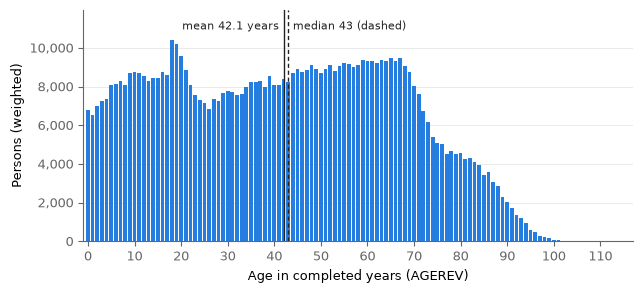

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.bar(df_age.index, df_age["persons"], width=0.8, color=BLUE, linewidth=0)
ax.axvline(mean_age, color=TEXT, lw=1.0)
ax.axvline(median_age, color=TEXT, lw=1.0, ls=(0, (3, 2)))
y_top = df_age["persons"].max()
ax.text(mean_age - 1.0, y_top * 1.04, f"mean {mean_age:.1f} years", fontsize=8, color=TEXT, va="bottom", ha="right")
ax.text(median_age + 1.0, y_top * 1.04, f"median {median_age:.0f} (dashed)", fontsize=8, color=TEXT, va="bottom")
ax.set_xlim(-1, df_age.index.max() + 1)
ax.set_ylim(0, y_top * 1.15)
ax.set_xticks(range(0, df_age.index.max() + 1, 10))
ax.set_xlabel("Age in completed years (AGEREV)")
ax.set_ylabel("Persons (weighted)")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="y", color=GRID, lw=0.6)
style_chart_axes(ax)
fig.tight_layout()
path = save_figure(fig, "age_distribution", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

## 2. Average age per municipality, youngest and oldest (1 point)

**Method.** The detailed file identifies only 17 municipalities (Ex. 1.1), so the mean age of **all 528**
municipalities is estimated from the age bands of the aggregated census: every person of a band is given the band
midpoint in completed years, $(l + u)/2$ (e.g. 25–39 → 32), and the open band 80+ is given **85 years**
(`AGE_OPEN_BAND`, an assumption; the actual weighted mean of 80+ in the detailed file is printed below):

$\hat a_i = \sum_b m_b\, P_{ib} / \sum_b P_{ib}$, with $P_{ib}$ the population of municipality $i$ in band $b$ and
$\sum_b P_{ib}$ = `P19_POP`.

**Validation.** The same band method is applied to the detailed census (department and the 17 identifiable
municipalities) and compared with the exact weighted mean from single-year ages. The difference isolates the error of
the band approximation; the band method on the aggregated file is shown as well (difference of source).

In [8]:
band_midpoints = pd.Series({c: (AGE_OPEN_BAND if hi is None else (lo + hi) / 2) for c, lo, hi in AGE_BANDS})
print("band midpoints:", band_midpoints.to_dict())


def band_mean_age(band_counts):
    # band_counts: DataFrame with the band columns (persons per band); returns the estimated mean age per row
    return band_counts[band_midpoints.index].mul(band_midpoints).sum(axis=1) / band_counts[band_midpoints.index].sum(axis=1)


# Detailed census in the same bands (weighted)
edges = [lo for _, lo, _ in AGE_BANDS] + [np.inf]
df_census["age_band"] = pd.cut(df_census["age"], bins=edges, right=False, labels=band_midpoints.index)
mean_age_80p = np.average(df_census.loc[df_census["age"] >= 80, "age"],
                          weights=df_census.loc[df_census["age"] >= 80, "weight"])
print("actual weighted mean age of the band 80+ (detailed census):", mean_age_80p)


def detailed_mean_ages(df):
    # exact weighted mean from single-year ages, and band-method estimate on the same persons
    exact = np.average(df["age"], weights=df["weight"])
    bands = df.groupby("age_band", observed=False)["weight"].sum().to_frame().T
    return exact, float(band_mean_age(bands).iloc[0])


df_population["mean_age_est"] = band_mean_age(df_population)

rows = []
exact, est = detailed_mean_ages(df_census)
rows.append({"municipality_id": DEPARTMENT, "name": f"{DEPARTMENT_NAME} (department)", "exact_detailed": exact,
             "band_detailed": est,
             "band_aggregated": float(band_mean_age(df_population[band_midpoints.index].sum().to_frame().T).iloc[0])})
for mid, df in df_census[df_census["municipality_id"].notna()].groupby("municipality_id"):
    exact, est = detailed_mean_ages(df)
    rows.append({"municipality_id": mid, "exact_detailed": exact, "band_detailed": est,
                 "band_aggregated": df_population.set_index("municipality_id").loc[mid, "mean_age_est"],
                 "name": df_population.set_index("municipality_id").loc[mid, "name"]})
df_age_validation = pd.DataFrame(rows).set_index("municipality_id")
df_age_validation["error_band"] = df_age_validation["band_detailed"] - df_age_validation["exact_detailed"]
df_age_validation["error_band_aggregated"] = df_age_validation["band_aggregated"] - df_age_validation["exact_detailed"]
df_age_validation = df_age_validation.sort_values("exact_detailed")

municipal = df_age_validation.drop(index=DEPARTMENT)
print("band method on the detailed file, 17 municipalities: mean error", municipal["error_band"].mean(),
      "| max |error|", municipal["error_band"].abs().max())
print("band method on the aggregated file vs exact:          mean error", municipal["error_band_aggregated"].mean(),
      "| max |error|", municipal["error_band_aggregated"].abs().max())
print("rank correlation exact vs aggregated estimate:",
      municipal["exact_detailed"].corr(municipal["band_aggregated"], method="spearman"))
df_age_validation

band midpoints: {'P19_POP0002': 1.0, 'P19_POP0305': 4.0, 'P19_POP0610': 8.0, 'P19_POP1117': 14.0, 'P19_POP1824': 21.0, 'P19_POP2539': 32.0, 'P19_POP4054': 47.0, 'P19_POP5564': 59.5, 'P19_POP6579': 72.0, 'P19_POP80P': 85.0}
actual weighted mean age of the band 80+ (detailed census): 85.73556940697628
band method on the detailed file, 17 municipalities: mean error 0.07842079914545048 | max |error| 0.2772672209908933
band method on the aggregated file vs exact:          mean error -0.04514649354348045 | max |error| 1.0870807441708124


rank correlation exact vs aggregated estimate: 0.9926470588235295


,name,exact_detailed,band_detailed,band_aggregated,error_band,error_band_aggregated
municipality_id,,,,,,
14327,Hérouville-Saint-Clair,37.848085,38.125353,38.110190,0.277267,0.262104
14118,Caen,38.723543,38.977430,38.988553,0.253886,0.265010
14341,Ifs,39.225665,39.402025,39.378331,0.176360,0.152666
14271,Fleury-sur-Orne,40.659147,40.787184,40.962256,0.128037,0.303109
14167,Colombelles,41.181517,41.411235,40.094437,0.229717,-1.087081
14301,Giberville,41.646942,41.590267,41.494629,-0.056674,-0.152312
14,Calvados (department),42.050441,42.128691,42.064339,0.078250,0.013898
14437,Mondeville,42.640577,42.886462,42.509965,0.245886,-0.130612
14333,Honfleur,43.154130,43.214233,43.470518,0.060103,0.316389


**Youngest and oldest municipality**, (a) over all 528 municipalities and (b) over the municipalities with at least
`MIN_POPULATION` = 500 inhabitants (`P19_POP`), because the mean age of a municipality of a few dozen inhabitants
depends on a handful of households.

In [9]:
show = ["municipality_id", "name", "P19_POP", "mean_age_est"]
large = df_population["P19_POP"] >= MIN_POPULATION
ranked_all = df_population.sort_values("mean_age_est")
ranked_large = df_population[large].sort_values("mean_age_est")

print(f"municipalities with >= {MIN_POPULATION} inhabitants: {large.sum()} of {len(df_population)} "
      f"({df_population.loc[large, 'P19_POP'].sum() / population_agg:.1%} of the population)")
print("estimated mean age over municipalities: min", df_population["mean_age_est"].min(),
      "| median", df_population["mean_age_est"].median(), "| max", df_population["mean_age_est"].max())
print("\n(a) all municipalities: 5 youngest and 5 oldest")
display(pd.concat([ranked_all.head(5), ranked_all.tail(5)])[show])
print(f"(b) municipalities with >= {MIN_POPULATION} inhabitants: 5 youngest and 5 oldest")
display(pd.concat([ranked_large.head(5), ranked_large.tail(5)])[show])

municipalities with >= 500 inhabitants: 242 of 528 (90.2% of the population)
estimated mean age over municipalities: min 30.866241965877915 | median 41.353579460510964 | max 56.89366831157827

(a) all municipalities: 5 youngest and 5 oldest


,municipality_id,name,P19_POP,mean_age_est
211,14297,Gavrus,584.0,30.866242
462,14674,Soignolles,128.0,32.799180
203,14285,Le Fournet,71.0,33.572368
68,14092,Bourguébus,2186.0,34.208244
58,14082,La Boissière,189.0,34.468254
153,14220,Deauville,3565.0,54.643788
133,14191,Courseulles-sur-Mer,4196.0,54.802004
377,14540,Rocques,289.0,56.313930
225,14312,Grandcamp-Maisy,1536.0,56.803792
480,14701,Tourgéville,782.0,56.893668


(b) municipalities with >= 500 inhabitants: 5 youngest and 5 oldest


,municipality_id,name,P19_POP,mean_age_est
211,14297,Gavrus,584.0,30.866242
68,14092,Bourguébus,2186.0,34.208244
283,14396,Maltot,1024.0,34.623767
28,14039,Barbery,824.0,34.863608
146,14207,Croisilles,646.0,35.128648
519,14754,Villers-sur-Mer,2543.0,53.865120
153,14220,Deauville,3565.0,54.643788
133,14191,Courseulles-sur-Mer,4196.0,54.802004
225,14312,Grandcamp-Maisy,1536.0,56.803792
480,14701,Tourgéville,782.0,56.893668


saved report\figures\mean_age_map.pdf


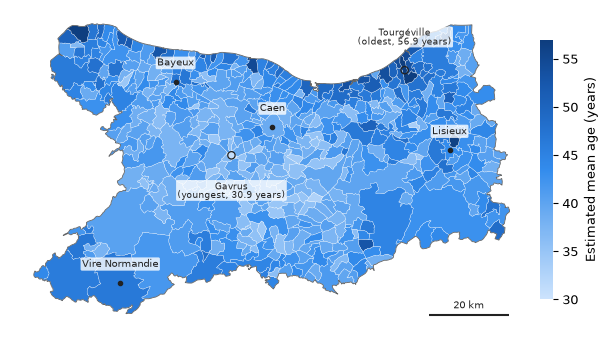

In [10]:
df_map = df_municipalities.merge(df_population[["municipality_id", "P19_POP", "mean_age_est"]],
                                 on="municipality_id", validate="1:1")
assert df_map["mean_age_est"].notna().all()

df_towns = df_map.set_index("municipality_id").loc[list(TOWNS)].copy()
df_towns["geometry"] = df_towns.geometry.representative_point()
extremes = {ranked_large.iloc[0]["municipality_id"]: "youngest", ranked_large.iloc[-1]["municipality_id"]: "oldest"}
df_extremes = df_map.set_index("municipality_id").loc[list(extremes)].copy()
df_extremes["geometry"] = df_extremes.geometry.representative_point()

fig, ax = plt.subplots(figsize=(6.5, 4.6))
vmin, vmax = np.floor(df_map["mean_age_est"].min()), np.ceil(df_map["mean_age_est"].max())
df_map.plot(ax=ax, column="mean_age_est", cmap=SEQUENTIAL, vmin=vmin, vmax=vmax, edgecolor="white", linewidth=0.2)
df_map.dissolve().boundary.plot(ax=ax, color=TEXT_2, linewidth=0.6)

df_towns.plot(ax=ax, color=TEXT, markersize=9, zorder=3)
for mid, row in df_towns.iterrows():
    ax.text(row.geometry.x, row.geometry.y + 4000, row["name"], fontsize=7, color=TEXT, ha="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)
df_extremes.plot(ax=ax, facecolor="none", edgecolor=TEXT, marker="o", markersize=28, linewidth=0.9, zorder=3)
EXTREME_OFFSETS = {"youngest": (0, -6500, "top"), "oldest": (0, 6000, "bottom")}   # label offsets (m), by eye
for mid, row in df_extremes.iterrows():
    kind = extremes[mid]
    dx, dy, va = EXTREME_OFFSETS[kind]
    ax.text(row.geometry.x + dx, row.geometry.y + dy, f"{row['name']}\n({kind}, {row['mean_age_est']:.1f} years)",
            fontsize=6.5, color=TEXT, ha="center", va=va, linespacing=1.0,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)

style_map_axes(ax)
scale_bar(ax, 20_000, "20 km", x_frac=0.80, y_frac=0.04)
sm = mpl.cm.ScalarMappable(cmap=SEQUENTIAL, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.01)
cbar.set_label("Estimated mean age (years)")
cbar.outline.set_visible(False)
fig.tight_layout()
path = save_figure(fig, "mean_age_map", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

## 3. Socio-professional categories: study area and at least three municipalities (1 point)

**Population.** All shares refer to the **population aged 15 and over**: the SPC counts of the aggregated census are
15+ (`C19_POP15P_CS*`), and in the detailed file `CS1` is only meaningful from 15 on. The dictionary has no separate code
for children; persons under 15 carry `CS1 = 8` (checked below), so without the filter category 8 would be inflated by
all children. The detailed file is filtered on `AGEREV >= 15`, which gives exactly `C19_POP15P`.

**Department.** Weighted shares from the detailed census, and from the aggregated file as a cross-check.

In [11]:
print("CS1 of persons with AGEREV < 15 (observations):",
      df_census.loc[df_census["age"] < 15, "csp"].value_counts().to_dict())
print("CS1 of persons with AGED < 15 (observations):  ",
      df_census.loc[df_census["age_aged"] < 15, "csp"].value_counts().to_dict())

df_15p = df_census[df_census["age"] >= 15]
spc_department_detailed = df_15p.groupby("csp")["weight"].sum() / df_15p["weight"].sum()
spc_department_aggregated = pd.Series({k: df_population[c].sum() for k, c in SPC_COLUMNS.items()}) / pop15_agg

df_spc_department = pd.DataFrame({
    "SPC": pd.Series(SPC_LABELS),
    "detailed": spc_department_detailed,
    "aggregated": spc_department_aggregated,
})
df_spc_department["difference (pp)"] = 100 * (df_spc_department["detailed"] - df_spc_department["aggregated"])
print("max |difference| (percentage points):", df_spc_department["difference (pp)"].abs().max())
df_spc_department

CS1 of persons with AGEREV < 15 (observations): {8: 28574, 5: 11, 6: 9, 4: 3, 1: 1}
CS1 of persons with AGED < 15 (observations):   {8: 26688, 5: 1}
max |difference| (percentage points): 5.551115123125783e-15


,SPC,detailed,aggregated,difference (pp)
1,Agriculteurs exploitants,0.009019,0.009019,-1.734723e-16
2,"Artisans, commerçants et chefs d'entreprise",0.035806,0.035806,-6.938894e-16
3,Cadres et professions intellectuelles supérieures,0.071639,0.071639,-1.387779e-15
4,Professions intermédiaires,0.134837,0.134837,2.775558e-15
5,Employés,0.161579,0.161579,-2.775558e-15
6,Ouvriers,0.128368,0.128368,0.000000e+00
7,Retraités,0.302728,0.302728,5.551115e-15
8,Autres personnes sans activité professionnelle,0.156024,0.156024,0.000000e+00


**Municipalities.** Four contrasting profiles:

- **Caen** (14118): the main city, regional university and administrative centre.
- **Hérouville-Saint-Clair** (14327): the largest suburb of Caen (a *ville nouvelle* of the 1960s–70s).
- **Trouville-sur-Mer** (14715): a seaside resort on the Côte Fleurie, known for many retirees and second homes.
- **A rural municipality**, chosen by a rule from the aggregated file: among the municipalities with 500 to 1,500
  inhabitants (`RURAL_POPULATION`), the one with the highest share of farmers (*agriculteurs exploitants*), i.e. the
  clearest agricultural profile among villages large enough for stable shares.

All municipality shares come from the aggregated file (same source for every area). Caen, Hérouville-Saint-Clair and
Trouville-sur-Mer are also identifiable in the detailed file, so their shares can be cross-checked.

In [12]:
spc_share_columns = {k: f"share_cs{k}" for k in SPC_LABELS}
for k, c in SPC_COLUMNS.items():
    df_population[spc_share_columns[k]] = df_population[c] / df_population["C19_POP15P"]

rural_candidates = df_population[df_population["P19_POP"].between(*RURAL_POPULATION)]
rural = rural_candidates.sort_values("share_cs1", ascending=False).iloc[0]
print(f"rural candidates ({RURAL_POPULATION[0]}-{RURAL_POPULATION[1]} inhabitants): {len(rural_candidates)}")
print("median farmer share among candidates:", rural_candidates["share_cs1"].median())
display(rural_candidates.sort_values("share_cs1", ascending=False).head(5)[
    ["municipality_id", "name", "P19_POP", "C19_POP15P", "share_cs1", "mean_age_est"]])

SELECTED = {
    "14118": "main city",
    "14327": "suburb",
    "14715": "seaside resort",
    rural["municipality_id"]: "rural",
}
df_selected = df_population.set_index("municipality_id").loc[list(SELECTED)]
df_spc = pd.DataFrame({f"{DEPARTMENT_NAME} (department)": spc_department_aggregated})
for mid, row in df_selected.iterrows():
    df_spc[row["name"]] = row[[spc_share_columns[k] for k in SPC_LABELS]].to_numpy(dtype=float)
df_spc.index = df_spc.index.map(SPC_LABELS)
print("population 15+ of the selected municipalities:", df_selected["C19_POP15P"].to_dict())
(100 * df_spc).round(1)

rural candidates (500-1500 inhabitants): 138
median farmer share among candidates: 0.011363636363636371


,municipality_id,name,P19_POP,C19_POP15P,share_cs1,mean_age_est
169,14240,Épaney,511.0,370.238785,0.108544,37.462494
424,14614,Sainte-Marguerite-d'Elle,779.0,620.710782,0.074100,42.798290
354,14504,Le Pin,813.0,615.000000,0.065041,39.197417
90,14124,La Cambe,546.0,481.977797,0.060784,45.794414
199,14281,Formigny La Bataille,735.0,594.683775,0.059598,42.572071


population 15+ of the selected municipalities: {'14118': 92552.39087869559, '14327': 18560.407867608457, '14715': 4075.70809878122, '14240': 370.238785379437}


,Calvados (department),Caen,Hérouville-Saint-Clair,Trouville-sur-Mer,Épaney
Agriculteurs exploitants,0.9,0.1,0.0,0.0,10.9
"Artisans, commerçants et chefs d'entreprise",3.6,2.1,1.8,5.3,6.8
Cadres et professions intellectuelles supérieures,7.2,11.0,6.2,3.5,9.4
Professions intermédiaires,13.5,13.5,13.7,8.6,12.0
Employés,16.2,14.6,18.9,16.9,17.4
Ouvriers,12.8,8.0,12.7,9.7,10.7
Retraités,30.3,22.4,23.5,46.0,20.6
Autres personnes sans activité professionnelle,15.6,28.2,23.1,10.1,12.2


In [13]:
# Cross-check: detailed vs aggregated shares for the selected municipalities that are identifiable in the detailed file
rows = []
for mid in SELECTED:
    df = df_15p[df_15p["municipality_id"] == mid]
    if df.empty:
        continue
    detailed = df.groupby("csp")["weight"].sum() / df["weight"].sum()
    aggregated = df_population.set_index("municipality_id").loc[mid, [spc_share_columns[k] for k in SPC_LABELS]]
    diff_pp = 100 * (detailed.reindex(SPC_LABELS, fill_value=0).to_numpy() - aggregated.to_numpy(dtype=float))
    rows.append({"municipality_id": mid, "name": df_selected.loc[mid, "name"],
                 "persons 15+ detailed": df["weight"].sum(),
                 "C19_POP15P": df_selected.loc[mid, "C19_POP15P"],
                 "max |difference| (pp)": np.abs(diff_pp).max()})
df_spc_crosscheck = pd.DataFrame(rows).set_index("municipality_id")
df_spc_crosscheck

,name,persons 15+ detailed,C19_POP15P,max |difference| (pp)
municipality_id,,,,
14118,Caen,92552.390879,92552.390879,8.326673e-15
14327,Hérouville-Saint-Clair,18560.407868,18560.407868,1.665335e-14
14715,Trouville-sur-Mer,4075.708099,4075.708099,1.054712e-13


saved report\figures\spc_distribution.pdf


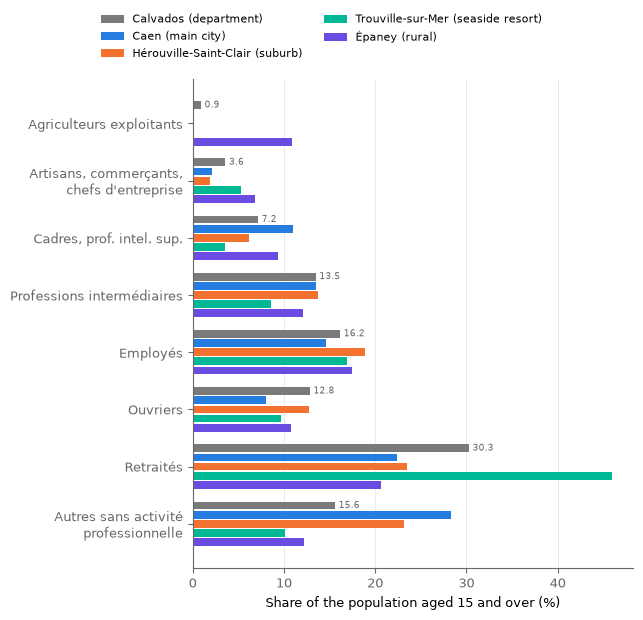

In [14]:
SPC_SHORT = {   # short axis labels (full names in the report table)
    1: "Agriculteurs exploitants", 2: "Artisans, commerçants,\nchefs d'entreprise",
    3: "Cadres, prof. intel. sup.", 4: "Professions intermédiaires", 5: "Employés", 6: "Ouvriers",
    7: "Retraités", 8: "Autres sans activité\nprofessionnelle",
}
areas = list(df_spc.columns)
colors = [REFERENCE, *AREA_COLORS]
n_areas = len(areas)
bar_h = 0.8 / n_areas

fig, ax = plt.subplots(figsize=(6.5, 6.2))
y = np.arange(len(SPC_LABELS))
for j, (area, color) in enumerate(zip(areas, colors)):
    values = 100 * df_spc[area].to_numpy()
    label = area if j == 0 else f"{area} ({SELECTED[df_selected.index[j - 1]]})"
    ax.barh(y + (j - (n_areas - 1) / 2) * bar_h, values, height=bar_h * 0.85, color=color, label=label, linewidth=0)
# Department value as text at the end of its (reference) bar
for i, v in enumerate(100 * df_spc[areas[0]].to_numpy()):
    ax.text(v + 0.4, y[i] - (n_areas - 1) / 2 * bar_h, f"{v:.1f}", fontsize=6.5, color=TEXT_2, va="center")
ax.set_yticks(y, [SPC_SHORT[k] for k in SPC_LABELS])
ax.invert_yaxis()
ax.set_xlabel("Share of the population aged 15 and over (%)")
ax.xaxis.grid(True, color=GRID, lw=0.6)
style_chart_axes(ax)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
path = save_figure(fig, "spc_distribution", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

In [15]:
# Differences to the department in percentage points (basis for the description)
df_spc_diff = 100 * df_spc.iloc[:, 1:].sub(df_spc.iloc[:, 0], axis=0)
df_spc_diff.round(1)

,Caen,Hérouville-Saint-Clair,Trouville-sur-Mer,Épaney
Agriculteurs exploitants,-0.8,-0.9,-0.9,10.0
"Artisans, commerçants et chefs d'entreprise",-1.4,-1.7,1.7,3.2
Cadres et professions intellectuelles supérieures,3.8,-0.9,-3.6,2.2
Professions intermédiaires,0.1,0.2,-4.9,-1.4
Employés,-1.5,2.8,0.7,1.3
Ouvriers,-4.8,-0.1,-3.2,-2.1
Retraités,-7.9,-6.8,15.7,-9.6
Autres personnes sans activité professionnelle,12.6,7.5,-5.5,-3.4


**Description** (numbers from the two tables above, population 15+, shares in %, differences in percentage points):

- **Caen** has almost twice the department share of "autres sans activité professionnelle" (28.2 vs 15.6, +12.6 pp;
  mostly students, Caen is a university city), more cadres (11.0 vs 7.2), fewer retirees (22.4 vs 30.3) and fewer
  ouvriers (8.0 vs 12.8).
- **Hérouville-Saint-Clair** also has more "autres sans activité" (23.1, +7.5 pp) and fewer retirees (23.5, −6.8 pp),
  but unlike Caen more employés (18.9 vs 16.2) and slightly fewer cadres (6.2 vs 7.2).
- **Trouville-sur-Mer**: retirees are 46.0 % of the population 15+ (+15.7 pp); professions intermédiaires (8.6) and
  cadres (3.5) are well below the department, artisans/commerçants slightly above (5.3 vs 3.6).
- **Épaney** (rural): farmers 10.9 % against 0.9 % in the department (+10.0 pp), more artisans (6.8) and fewer
  retirees (20.6, −9.6 pp). Its shares rest on only 370 persons aged 15+, so single categories are uncertain.

## Results for the report

All numbers of Section 1.2 come from this file (unrounded).

In [16]:
def records(df, columns):
    return {str(k): {c: (v[c].item() if hasattr(v[c], "item") else v[c]) for c in columns} for k, v in df.iterrows()}


results = {
    "age_variable": "AGEREV (age in completed years); AGED reported for comparison",
    "aggregated_file": AGGREGATED_CSV.name,
    "department": {
        "n_observations": int(len(df_census)),
        "n_persons_weighted": float(n_persons_detailed),
        "mean_age": float(mean_age),
        "median_age": int(median_age),
        "mean_age_unweighted": float(mean_age_unweighted),
        "mean_age_aged": float(mean_age_aged),
        "share_65_plus": float(share_65p),
        "share_under_20": float(share_under20),
        "age_mode": age_mode,
        "age_mode_under_30": age_mode_under30,
        "age_trough_20_40": age_trough_20_40,
    },
    "aggregated_census": {
        "n_iris": int(len(df_agg_iris)),
        "n_municipalities": int(len(df_population)),
        "municipalities_not_in_ign": sorted(agg - ign),
        "municipalities_not_in_aggregated": sorted(ign - agg),
        "P19_POP": float(population_agg),
        "difference_detailed_minus_P19_POP": float(n_persons_detailed - population_agg),
        "C19_POP15P": float(pop15_agg),
        "detailed_persons_15p": float(pop15_detailed),
        "band_check_max_rel_diff_agerev": float(df_band_check["rel. diff. AGEREV"].abs().max()),
        "band_check_max_rel_diff_aged": float(df_band_check["rel. diff. AGED"].abs().max()),
    },
    "band_method": {
        "midpoints": band_midpoints.to_dict(),
        "open_band_assumption": AGE_OPEN_BAND,
        "actual_mean_age_80p_detailed": float(mean_age_80p),
        "mean_error_17_municipalities": float(municipal["error_band"].mean()),
        "max_abs_error_17_municipalities": float(municipal["error_band"].abs().max()),
        "mean_error_aggregated_17_municipalities": float(municipal["error_band_aggregated"].mean()),
        "max_abs_error_aggregated_17_municipalities": float(municipal["error_band_aggregated"].abs().max()),
        "validation": records(df_age_validation, ["name", "exact_detailed", "band_detailed", "band_aggregated",
                                                  "error_band", "error_band_aggregated"]),
    },
    "mean_age_municipalities": {
        "min": float(df_population["mean_age_est"].min()),
        "median": float(df_population["mean_age_est"].median()),
        "max": float(df_population["mean_age_est"].max()),
        "min_population_threshold": MIN_POPULATION,
        "n_municipalities_above_threshold": int(large.sum()),
        "share_population_above_threshold": float(df_population.loc[large, "P19_POP"].sum() / population_agg),
        "all_youngest5": records(ranked_all.head(5).set_index("municipality_id"), ["name", "P19_POP", "mean_age_est"]),
        "all_oldest5": records(ranked_all.tail(5).set_index("municipality_id"), ["name", "P19_POP", "mean_age_est"]),
        "large_youngest5": records(ranked_large.head(5).set_index("municipality_id"), ["name", "P19_POP", "mean_age_est"]),
        "large_oldest5": records(ranked_large.tail(5).set_index("municipality_id"), ["name", "P19_POP", "mean_age_est"]),
    },
    "spc": {
        "population": "15 and over (AGEREV >= 15 / C19_POP15P)",
        "department_detailed": {SPC_LABELS[k]: float(v) for k, v in spc_department_detailed.items()},
        "department_aggregated": {SPC_LABELS[k]: float(v) for k, v in spc_department_aggregated.items()},
        "department_max_abs_difference_pp": float(df_spc_department["difference (pp)"].abs().max()),
        "selected_municipalities": {mid: {"name": df_selected.loc[mid, "name"], "role": role,
                                          "P19_POP": float(df_selected.loc[mid, "P19_POP"]),
                                          "C19_POP15P": float(df_selected.loc[mid, "C19_POP15P"])}
                                    for mid, role in SELECTED.items()},
        "rural_rule": f"highest share_cs1 among {RURAL_POPULATION[0]}-{RURAL_POPULATION[1]} inhabitants",
        "n_rural_candidates": int(len(rural_candidates)),
        "shares": {area: {spc: float(v) for spc, v in df_spc[area].items()} for area in df_spc.columns},
        "crosscheck_detailed_vs_aggregated": records(df_spc_crosscheck, ["name", "persons 15+ detailed", "C19_POP15P",
                                                                        "max |difference| (pp)"]),
    },
}
RESULTS_JSON.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", RESULTS_JSON.relative_to(ROOT))
results["department"]

saved data\processed\ex12_results.json


{'n_observations': 171834,
 'n_persons_weighted': 695131.5553559497,
 'mean_age': 42.050440863357,
 'median_age': 43,
 'mean_age_unweighted': 41.23960915767543,
 'mean_age_aged': 43.0004121129536,
 'share_65_plus': 0.21496988323150845,
 'share_under_20': 0.2377430038088101,
 'age_mode': 18,
 'age_mode_under_30': 18,
 'age_trough_20_40': 26}

## Problems encountered

- **Municipalities not identifiable in the detailed census** (Ex. 1.1): only 17 of 528 municipalities. The map and the
  youngest/oldest municipality therefore use the aggregated census by IRIS, which only has age **bands**; the mean age
  per municipality is a band-midpoint estimate (open band 80+ set to 85). Validated on the 17 identifiable
  municipalities (table in Section 2).
- **Two age variables.** The detailed file has `AGED` (age reached during the census year) and `AGEREV` (age in
  completed years); `AGED` is on average about one year higher. The aggregated age bands are in completed years, so
  `AGEREV` is used throughout; `census_14.parquet` stores it as `age` (and `AGED` as `age_aged`, for the comparison).
- **Two exploitations of the census.** `P19_POP` (exploitation principale) is the official population 694,905, while the
  weights of the detailed file and the `C19_*` SPC counts (exploitation complémentaire) give 695,132 persons. Mean ages
  from the two sources therefore differ slightly for single municipalities (up to about one year for Colombelles).
- **SPC of children.** `CS1` is coded 8 ("autres sans activité") for persons under 15, which would inflate category 8;
  all SPC shares use the population 15+. A few observations with `AGEREV = 14` carry another `CS1` (they turn 15 during
  the census year, `AGED = 15`); with `AGEREV >= 15` the detailed file reproduces `C19_POP15P` exactly.
- **Small municipalities.** Mean ages and SPC shares of very small municipalities rest on few persons; the youngest and
  oldest municipality are therefore also given for municipalities with at least 500 inhabitants (here the result is
  the same), and the rural example has at least 500 inhabitants.